# Finetuning de Stable Diffusion v1-4 con LoRA
## Dataset: `gigant/oldbookillustrations` (ilustraciones de libros antiguos, 1800-1900)

Entrega final del Módulo de Modelos de Generación de Imagen.

**Objetivo:** modificar el comportamiento de Stable Diffusion v1-4 mediante la técnica de LoRA
para que, ante un prompt neutro, genere imágenes con la estética de grabado a plumilla del siglo XIX
en lugar de la pintura o el render que produce por defecto.

### Decisiones de diseño

| Decisión | Valor | Motivo |
|---|---|---|
| Entorno | Google Colab, GPU T4 | Suficiente con LoRA: solo se entrena el 0,19% de los parámetros |
| Precisión | fp32 | Máxima fidelidad numérica en el entrenamiento |
| Muestras | 830 (20% del dataset) | Equilibrio entre tiempo de entrenamiento y señal suficiente |
| Filtrado | caption no vacía, ≥15 caracteres, idioma inglés | CLIP se entrenó en inglés y el dataset es multilingüe (en/fr/de) |
| Muestreo | aleatorio con semilla fija | El dataset está ordenado por origen: tomar las primeras filas sesgaría el estilo hacia un único ilustrador |
| Transformación | `Resize(512)` del lado corto + `CenterCrop(512)` | Las ilustraciones no son cuadradas; un `Resize((512,512))` las deformaría |
| LoRA | `r=8`, `alpha=8`, capas de atención | Aprender un estilo gráfico no requiere rangos altos |
| Entrenamiento | 5 épocas, batch 3, lr 1e-4 | 277 pasos por época, 1.385 pasos en total |
| Prompt de evaluación | `a sailing ship at sea` | Sin palabras de estilo: el cambio debe aparecer sin pedirlo |
| Reproducibilidad | seed 42, 50 pasos, guidance 7.5 | Idénticos antes y después |

### Índice

0. Instalación de librerías
1. Comportamiento original del modelo pre-entrenado
2. Dataset: carga, filtrado y transformaciones
3. Componentes del modelo por separado
4. Inyección de la LoRA
5. Entrenamiento
6. Comportamiento del modelo finetuneado
7. Subida a Hugging Face
8. Recarga del modelo desde Hugging Face
9. Conclusiones

# 0. Instalación de librerías

In [1]:
!pip install -qq diffusers datasets accelerate peft langdetect

# Colab trae preinstalada una version antigua de torchao incompatible con peft.
# peft solo la usa para cuantizacion, que aqui no necesitamos.
!pip uninstall -qq -y torchao

In [2]:
import os
import torch
from tqdm import tqdm
from PIL import Image

from diffusers import StableDiffusionPipeline, DDPMScheduler
from diffusers import UNet2DConditionModel, AutoencoderKL
from diffusers.utils import convert_state_dict_to_diffusers
from transformers import CLIPTextModel, CLIPTokenizer
from datasets import load_dataset
from accelerate import Accelerator
from peft import LoraConfig
from peft.utils import get_peft_model_state_dict
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)
if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM:", round(torch.cuda.get_device_properties(0).total_memory / 1e9, 1), "GB")

Device: cuda
GPU: Tesla T4
VRAM: 15.6 GB


### Configuración

Todos los hiperparámetros del proyecto reunidos en una sola celda, de forma que el resto del
notebook no contenga ningún valor codificado a mano.

In [ ]:
# --- Modelo base ---
pretrained_model_name = "CompVis/stable-diffusion-v1-4"
resolution = 512            # resolucion nativa de SD v1-4 (segun su model card)

# --- Dataset ---
dataset_name = "gigant/oldbookillustrations"
COL_IMAGEN = "1600px"       # columna con la imagen limpia (lado largo de 1600 px)
COL_TEXTO = "info_alt"      # columna con la descripcion corta
MIN_CARACTERES = 15         # las captions mas cortas se descartan
IDIOMA = "en"               # CLIP se entreno esencialmente en ingles
N_MUESTRAS = 830            # 20% del dataset
SEED_DATOS = 42             # semilla del muestreo: garantiza las mismas 830 imagenes

# --- LoRA ---
lora_rank = 8
lora_alpha = 8
adapter_name = "oldbooks"

# --- Entrenamiento ---
batch_size = 3              # limite practico de la T4 en fp32 a 512 px
learning_rate = 1e-4
num_epochs = 5

# --- Evaluacion (identica antes y despues) ---
PROMPT = "a sailing ship at sea"
PROMPT_CONTROL = "a portrait of a man with a beard"
SEED = 42
NUM_STEPS = 50
GUIDANCE = 7.5

# --- Salidas ---
OUTPUT_DIR = "lora_oldbooks"
REPO_NOMBRE = "sd-v1-4-oldbook-illustrations-lora"

os.makedirs("imagenes", exist_ok=True)
print(f"{N_MUESTRAS} imagenes | {num_epochs} epocas | batch {batch_size}")

# 1. Comportamiento original del modelo pre-entrenado

Generamos la imagen de referencia *antes* del finetuning. Prompt, semilla, número de pasos y
guidance quedan fijados aquí y no vuelven a modificarse: cualquier cambio entre el antes y el
después invalidaría la comparación.

El prompt no contiene ninguna palabra de estilo (`engraving`, `vintage`, `19th century`...). El
modelo base ya sabe dibujar grabados si se le piden explícitamente, de modo que pedirlos no
demostraría nada. El objetivo es que el estilo aparezca **sin** solicitarlo.

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

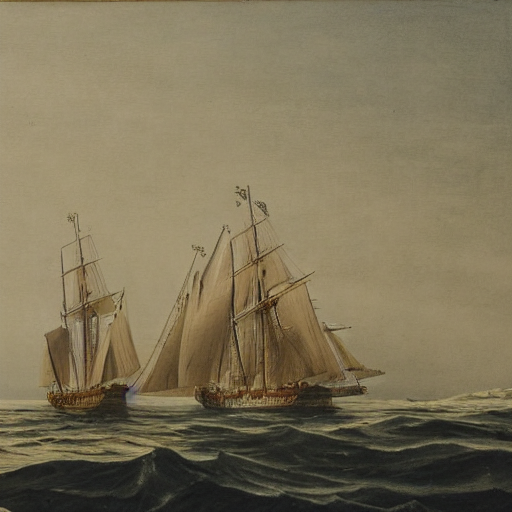

In [3]:
pipe = StableDiffusionPipeline.from_pretrained(
    pretrained_model_name,
    safety_checker=None,            # desactivado en ambos casos para que la comparacion sea simetrica
    requires_safety_checker=False,
).to(device)

generator = torch.Generator(device=device).manual_seed(SEED)
imagen_antes = pipe(
    PROMPT,
    generator=generator,
    num_inference_steps=NUM_STEPS,
    guidance_scale=GUIDANCE,
).images[0]

imagen_antes.save("imagenes/antes_sailing_ship.png")
imagen_antes

  0%|          | 0/50 [00:00<?, ?it/s]

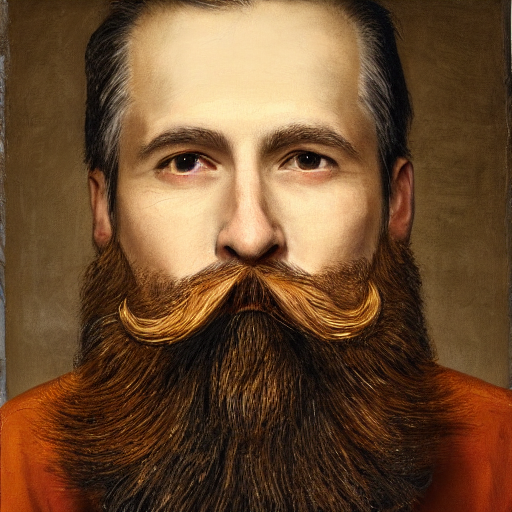

In [4]:
# Segundo prompt, sin relacion con el contenido del dataset. Servira para distinguir si la LoRA
# aprende una estetica generalizable o si memoriza contenido concreto.
generator = torch.Generator(device=device).manual_seed(SEED)
imagen_antes_control = pipe(
    PROMPT_CONTROL,
    generator=generator,
    num_inference_steps=NUM_STEPS,
    guidance_scale=GUIDANCE,
).images[0]

imagen_antes_control.save("imagenes/antes_portrait.png")
imagen_antes_control

In [5]:
# Liberamos la GPU antes de cargar las componentes por separado:
# de lo contrario no habria VRAM suficiente para VAE + CLIP + UNet.
del pipe
torch.cuda.empty_cache()
print("GPU liberada")

GPU liberada


# 2. Dataset: carga, filtrado y transformaciones

El dataset presenta tres particularidades frente al de Pokémon utilizado en clase:

1. **Las columnas se llaman distinto**: `1600px` e `info_alt` en lugar de `image` y `text`.
   Incluye además una columna `rawscan` con el escaneo en bruto, innecesaria para este trabajo y
   la que más pesa, así que se descarta nada más cargar.
2. **Las ilustraciones no son cuadradas**: el lado largo mide 1600 px y el otro varía.
3. **Es multilingüe** (inglés, francés y alemán) y algunas captions vienen vacías.

In [6]:
# La descarga son ~5 GB la primera vez (13 ficheros parquet), que quedan cacheados.
dataset = load_dataset(dataset_name, split="train")
print(dataset)

# Nos quedamos solo con las dos columnas necesarias. Esto evita que datasets decodifique
# los escaneos en bruto en cada acceso a una fila.
dataset = dataset.select_columns([COL_IMAGEN, COL_TEXTO])
print("\nTras seleccionar columnas:", dataset.column_names)

Dataset({
    features: ['rawscan', '1600px', 'info_url', 'info_src', 'info_alt', 'artist_name', 'artist_birth_date', 'artist_death_date', 'artist_countries', 'book_title', 'book_authors', 'book_publishers', 'date_published', 'openlibrary-url', 'tags', 'illustration_source_name', 'illustration_source_url', 'illustration_subject', 'illustration_format', 'engravers', 'image_title', 'image_caption', 'image_description', 'rawscan_url', '1600px_url'],
    num_rows: 4154
})

Tras seleccionar columnas: ['1600px', 'info_alt']


Caption: A bald man with a long beard smiles faintly as he carries on his back a little girl wearing his hat
Tamano de la imagen: (1158, 1600) | modo: RGB


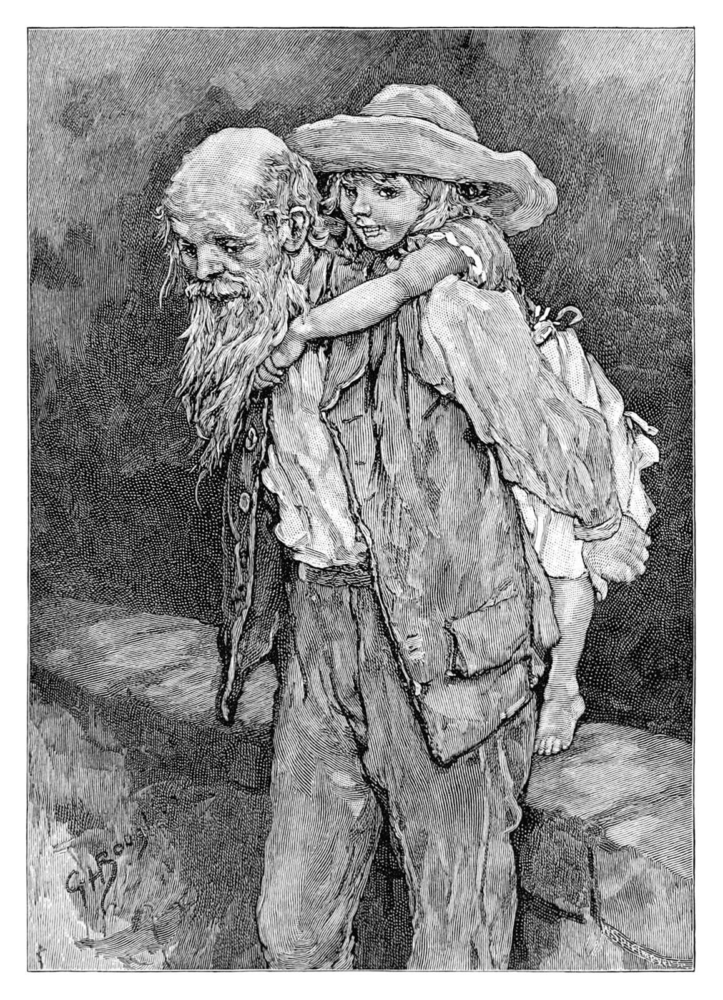

In [7]:
# Inspeccion de un ejemplo antes de transformar nada:
ejemplo = dataset[0]
print("Caption:", ejemplo[COL_TEXTO])
print("Tamano de la imagen:", ejemplo[COL_IMAGEN].size, "| modo:", ejemplo[COL_IMAGEN].mode)
ejemplo[COL_IMAGEN]

### Filtrado de captions

Se descarta `dataset.filter()` por un motivo de rendimiento: ese método recorre las filas completas
y acabaría decodificando 4.154 imágenes de 1600 px únicamente para leer un campo de texto.

En su lugar se extrae solo la columna de texto, que es una lectura directa de Arrow y no toca las
imágenes, se deciden los índices válidos en Python puro y se seleccionan al final.

El mínimo de 15 caracteres cumple una doble función: descarta captions pobres y proporciona
material suficiente a `langdetect`, poco fiable con frases muy cortas.

In [8]:
from langdetect import detect, DetectorFactory
DetectorFactory.seed = 0   # langdetect es no determinista si no se fija la semilla

captions = dataset[COL_TEXTO]   # solo texto: no decodifica ninguna imagen

def es_valida(c):
    if c is None or len(c.strip()) < MIN_CARACTERES:
        return False
    try:
        return detect(c) == IDIOMA
    except Exception:
        return False

indices_validos = [i for i, c in enumerate(tqdm(captions, desc="Filtrando")) if es_valida(c)]

print(f"\nCaptions validas: {len(indices_validos)} de {len(captions)} "
      f"({100 * len(indices_validos) / len(captions):.1f}%)")

Filtrando: 100%|██████████| 4154/4154 [00:20<00:00, 198.51it/s]


Captions validas: 3382 de 4154 (81.4%)


In [9]:
# Barajamos con semilla fija y tomamos N_MUESTRAS.
# El shuffle es imprescindible: el dataset viene ordenado por libro y artista, de modo que
# tomar las primeras N sesgaria el estilo aprendido hacia un unico ilustrador.
dataset = dataset.select(indices_validos).shuffle(seed=SEED_DATOS)
dataset = dataset.select(range(min(N_MUESTRAS, len(dataset))))

print(f"Dataset final: {len(dataset)} imagenes")
print("Ejemplos de captions:")
for c in dataset[COL_TEXTO][:5]:
    print(" -", c)

Dataset final: 830 imagenes
Ejemplos de captions:
 - A dancing woman is leaping to the sound of a tambourine, her hair floating around her head
 - A ship has been brought under a masting sheer and is having one of its masts put into place
 - But right or left as strikes the player goes
 - A cat with fiery eyes stands arching her back on a branch of an apple tree
 - Puss stands on the bank of a pond where his owner is bathing and gestures toward a carriage


### Transformaciones

La clave está en pasar un **entero** a `Resize` en lugar de una tupla:

- `Resize((512, 512))` fuerza ambas dimensiones y **deforma** la ilustración.
- `Resize(512)` lleva el lado **corto** a 512 manteniendo la proporción, y el `CenterCrop`
  posterior recorta el cuadrado central.

Se pierden los bordes, que en estas ilustraciones suelen contener el marco y el pie de imagen
grabado. Resulta deseable: no interesa que el modelo aprenda a dibujar texto.

In [ ]:
image_transforms = transforms.Compose([
    transforms.Resize(resolution),                           # lado CORTO a 512, proporciones intactas
    transforms.CenterCrop(resolution),                       # cuadrado central de 512x512
    transforms.ToTensor(),                                   # [0,1]
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),  # [-1,1], que es lo que espera el VAE
])

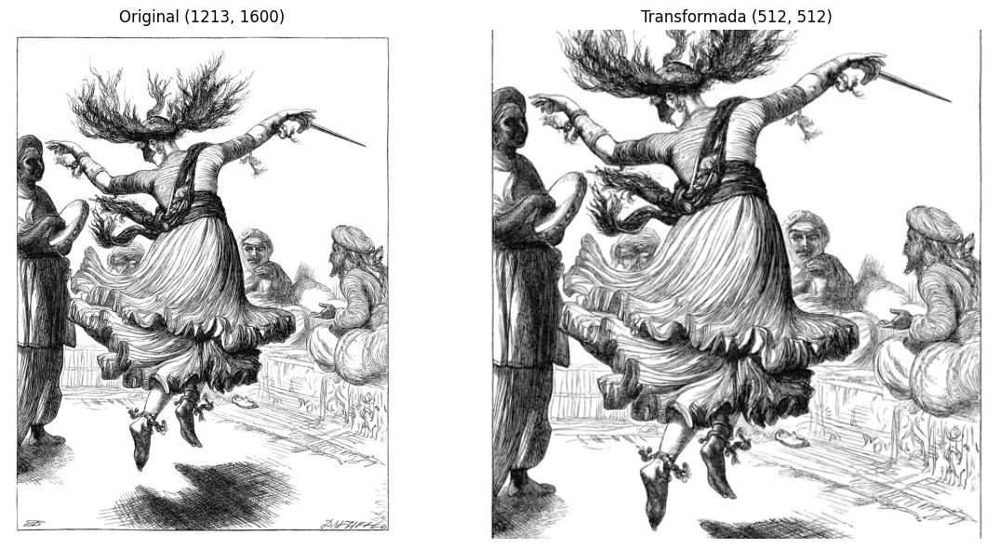

In [10]:
# Comprobacion visual: original frente a transformada
import matplotlib.pyplot as plt

original = dataset[0][COL_IMAGEN].convert("RGB")
tensor = image_transforms(original)
transformada = transforms.ToPILImage()(tensor * 0.5 + 0.5)   # deshacemos la normalizacion para verla

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
axes[0].imshow(original); axes[0].set_title(f"Original {original.size}"); axes[0].axis("off")
axes[1].imshow(transformada); axes[1].set_title(f"Transformada {transformada.size}"); axes[1].axis("off")
plt.tight_layout(); plt.show()

# 3. Componentes del modelo por separado

Para entrenar hace falta acceso individual a cada pieza, no al pipeline cerrado:

- **Tokenizer** y **text encoder (CLIP)**: convierten la caption en un vector de condicionamiento.
- **VAE**: lleva la imagen al espacio latente, donde ocurre todo el proceso de difusión.
- **Scheduler**: define cómo se añade el ruido en el proceso hacia delante.
- **UNet**: la única que se entrena, y solo a través de la LoRA.

El VAE y el text encoder se congelan explícitamente. La UNet quedará congelada de forma automática
cuando `peft` inyecte la LoRA en el paso siguiente.

In [11]:
tokenizer = CLIPTokenizer.from_pretrained(pretrained_model_name, subfolder="tokenizer")
noise_scheduler = DDPMScheduler.from_pretrained(pretrained_model_name, subfolder="scheduler")
text_encoder = CLIPTextModel.from_pretrained(pretrained_model_name, subfolder="text_encoder").to(device)
vae = AutoencoderKL.from_pretrained(pretrained_model_name, subfolder="vae").to(device)
unet = UNet2DConditionModel.from_pretrained(pretrained_model_name, subfolder="unet").to(device)

vae.eval()
text_encoder.eval()
for p in vae.parameters():
    p.requires_grad = False
for p in text_encoder.parameters():
    p.requires_grad = False

print("Componentes cargadas y congeladas (VAE + text encoder)")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Componentes cargadas y congeladas (VAE + text encoder)


### Preprocesado

La transformación se separa en dos partes. La geométrica (`Resize` + `CenterCrop`) es la costosa y
se aplica una sola vez sobre las 830 ilustraciones; la conversión a tensor es trivial y se hace en
cada acceso. Así el trabajo de decodificar imágenes de 1600 px no se repite en cada una de las
cinco épocas. Las captions se tokenizan también de una vez.

Al ser el recorte determinista (`CenterCrop`, no aleatorio), precalcular no sacrifica ningún
aumento de datos: cada época recibía ya exactamente la misma imagen.

In [12]:
geom_transforms = transforms.Compose([
    transforms.Resize(resolution),
    transforms.CenterCrop(resolution),
])
tensor_transforms = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
])

imagenes_pre, captions_pre = [], []
for ejemplo in tqdm(dataset, desc="Preprocesando"):
    imagenes_pre.append(geom_transforms(ejemplo[COL_IMAGEN].convert("RGB")))
    captions_pre.append(ejemplo[COL_TEXTO])

tokens_pre = tokenizer(
    captions_pre, padding="max_length", truncation=True,
    max_length=tokenizer.model_max_length, return_tensors="pt",
).input_ids

print(f"{len(imagenes_pre)} imágenes en memoria a {imagenes_pre[0].size}")
print(f"Ocupación aproximada: {len(imagenes_pre) * resolution * resolution * 3 / 1e6:.0f} MB")

Preprocesando: 100%|██████████| 830/830 [00:26<00:00, 30.78it/s]

830 imágenes en memoria a (512, 512)
Ocupación aproximada: 653 MB


In [13]:
class Text2ImageDataset(Dataset):
    """Devuelve el tensor de la imagen y los tokens de su caption."""

    def __init__(self, imagenes, input_ids):
        self.imagenes = imagenes
        self.input_ids = input_ids

    def __len__(self):
        return len(self.imagenes)

    def __getitem__(self, idx):
        return {
            "pixel_values": tensor_transforms(self.imagenes[idx]),
            "input_ids": self.input_ids[idx],
        }

train_dataset = Text2ImageDataset(imagenes_pre, tokens_pre)

# num_workers=0: el trabajo por muestra es ahora trivial, y cada worker duplicaria
# las imagenes en RAM sin ganancia alguna.
train_dataloader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=0)

print(f"{len(train_dataset)} muestras | {len(train_dataloader)} pasos por época")

830 muestras | 277 pasos por época


# 4. Inyección de la LoRA

En lugar de reentrenar los ~860M de parámetros de la UNet, sus pesos se congelan y en las capas de
atención (`to_q`, `to_k`, `to_v`, `to_out.0`) se añaden dos matrices pequeñas de rango `r` cuyo
producto se suma al peso original: `W = W0 + BA`.

Consecuencias prácticas:

- Se entrena menos del 1% de los parámetros.
- El fichero resultante pesa unos MB en lugar de ~3,4 GB.
- El adaptador se puede activar, desactivar o graduar en intensidad sobre el modelo base.

In [14]:
lora_config = LoraConfig(
    r=lora_rank,
    lora_alpha=lora_alpha,
    init_lora_weights="gaussian",
    target_modules=["to_k", "to_q", "to_v", "to_out.0"],
)
unet.add_adapter(lora_config, adapter_name=adapter_name)

lora_params = [p for p in unet.parameters() if p.requires_grad]
n_lora = sum(p.numel() for p in lora_params)
n_total = sum(p.numel() for p in unet.parameters())
print(f"Parametros entrenables (LoRA): {n_lora:,} de {n_total:,} ({100 * n_lora / n_total:.2f}%)")

# El optimizador recibe SOLO los parametros de la LoRA.
optimizer = torch.optim.AdamW(lora_params, lr=learning_rate)

accelerator = Accelerator()
unet, optimizer, train_dataloader = accelerator.prepare(unet, optimizer, train_dataloader)
print("Accelerator listo en", accelerator.device)

Parametros entrenables (LoRA): 1,594,368 de 861,115,332 (0.19%)
Accelerator listo en cuda


# 5. Entrenamiento

El bucle es el mismo que el de un finetuning completo:

1. El VAE codifica la imagen al espacio latente.
2. Se genera ruido aleatorio y se elige un timestep aleatorio.
3. El scheduler añade ese ruido al latente (proceso de difusión hacia delante).
4. CLIP codifica la caption.
5. La UNet predice el ruido a partir del latente ruidoso, el timestep y el texto.
6. Se calcula el MSE entre el ruido predicho y el real, y se retropropaga.

La única diferencia es que el optimizador actualiza exclusivamente las matrices de la LoRA.

### Sobre la loss

La loss **no sirve como métrica de éxito en este problema**. Cada paso sortea un timestep aleatorio,
y predecir el ruido en t=900 (imagen casi pura estática) es mucho más fácil que en t=50. Esa
aleatoriedad domina la señal: el valor individual salta entre magnitudes muy distintas sin que ello
signifique nada, y la media por época apenas se mueve aunque el modelo esté aprendiendo.

La validación real en un modelo generativo consiste en generar una imagen y examinarla.

Cada época guarda su propio checkpoint. Son ficheros de pocos MB y permiten comparar la evolución
del estilo o recuperar un estado anterior sin repetir el entrenamiento.

In [ ]:
def guardar_lora(directorio):
    """Extrae los pesos de la LoRA y los guarda en formato diffusers (.safetensors)."""
    unet_sin_envolver = accelerator.unwrap_model(unet)
    state_dict = convert_state_dict_to_diffusers(
        get_peft_model_state_dict(unet_sin_envolver, adapter_name=adapter_name)
    )
    StableDiffusionPipeline.save_lora_weights(
        save_directory=directorio,
        unet_lora_layers=state_dict,
        safe_serialization=True,
    )
    return directorio

In [15]:
unet.train()
historial = []

for epoch in range(num_epochs):
    losses = []
    progress_bar = tqdm(train_dataloader, desc=f"Epoca {epoch + 1}/{num_epochs}")

    for batch in progress_bar:

        # 1. Imagen -> espacio latente (el VAE esta congelado, no necesita gradientes)
        with torch.no_grad():
            latents = vae.encode(batch["pixel_values"].to(accelerator.device)).latent_dist.sample()
            latents = latents * 0.18215   # factor de escala propio del VAE de SD

        # 2. Proceso de difusion hacia delante
        noise = torch.randn_like(latents)
        timesteps = torch.randint(
            0, noise_scheduler.config.num_train_timesteps,
            (latents.shape[0],), device=latents.device,
        ).long()
        noisy_latents = noise_scheduler.add_noise(latents, noise, timesteps)

        # 3. Condicionamiento por texto
        encoder_hidden_states = text_encoder(batch["input_ids"].to(accelerator.device))[0]

        # 4. Prediccion del ruido
        noise_pred = unet(noisy_latents, timesteps, encoder_hidden_states).sample

        # 5. Error y actualizacion (solo parametros de la LoRA)
        loss = torch.nn.functional.mse_loss(noise_pred, noise)
        accelerator.backward(loss)
        optimizer.step()
        optimizer.zero_grad()

        losses.append(loss.item())
        progress_bar.set_postfix(loss=f"{loss.item():.4f}")

    media = sum(losses) / len(losses)
    historial.append(media)
    print(f"Epoca {epoch + 1} -> loss media: {media:.4f}")

    # Checkpoint tras cada epoca, cada uno en su propia carpeta
    guardar_lora(f"{OUTPUT_DIR}_ep{epoch + 1}")
    print(f"   LoRA guardada en {OUTPUT_DIR}_ep{epoch + 1}")

guardar_lora(OUTPUT_DIR)
print(f"\nVersion final guardada en {OUTPUT_DIR}")
print("Historial de loss media:", [round(x, 4) for x in historial])

Epoca 1/5: 100%|██████████| 277/277 [18:02<00:00,  3.91s/it, loss=0.2323]


Epoca 1 -> loss media: 0.1551
   LoRA guardada en lora_oldbooks_ep1


Epoca 2/5: 100%|██████████| 277/277 [18:01<00:00,  3.90s/it, loss=0.0344]


Epoca 2 -> loss media: 0.1580
   LoRA guardada en lora_oldbooks_ep2


Epoca 3/5: 100%|██████████| 277/277 [18:01<00:00,  3.90s/it, loss=0.4702]


Epoca 3 -> loss media: 0.1433
   LoRA guardada en lora_oldbooks_ep3


Epoca 4/5: 100%|██████████| 277/277 [18:01<00:00,  3.90s/it, loss=0.1906]


Epoca 4 -> loss media: 0.1514
   LoRA guardada en lora_oldbooks_ep4


Epoca 5/5: 100%|██████████| 277/277 [18:00<00:00,  3.90s/it, loss=0.0331]

Epoca 5 -> loss media: 0.1574
   LoRA guardada en lora_oldbooks_ep5

Version final guardada en lora_oldbooks
Historial de loss media: [0.1551, 0.158, 0.1433, 0.1514, 0.1574]


In [16]:
# Tamano del fichero resultante: compara esto con los ~3.4 GB de la UNet completa.
for f in os.listdir(OUTPUT_DIR):
    print(f, "->", round(os.path.getsize(os.path.join(OUTPUT_DIR, f)) / 1e6, 2), "MB")

pytorch_lora_weights.safetensors -> 6.41 MB


# 6. Comportamiento del modelo finetuneado

Se reutilizan las componentes que ya están en GPU: la UNet recién entrenada lleva la LoRA inyectada
dentro, de modo que basta con montar el pipeline con ella.

Mismo prompt, misma semilla, mismos pasos y mismo guidance que en la sección 1.

In [17]:
unet = accelerator.unwrap_model(unet)
unet.eval()

pipe = StableDiffusionPipeline.from_pretrained(
    pretrained_model_name,
    unet=unet,
    vae=vae,
    text_encoder=text_encoder,
    tokenizer=tokenizer,
    safety_checker=None,
    requires_safety_checker=False,
).to(device)

# Intensidad del adaptador: 0 = modelo base puro, 1 = LoRA al factor de escala nominal
pipe.set_adapters([adapter_name], adapter_weights=[1.0])
print("Pipeline con LoRA listo")

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Pipeline con LoRA listo


  0%|          | 0/50 [00:00<?, ?it/s]

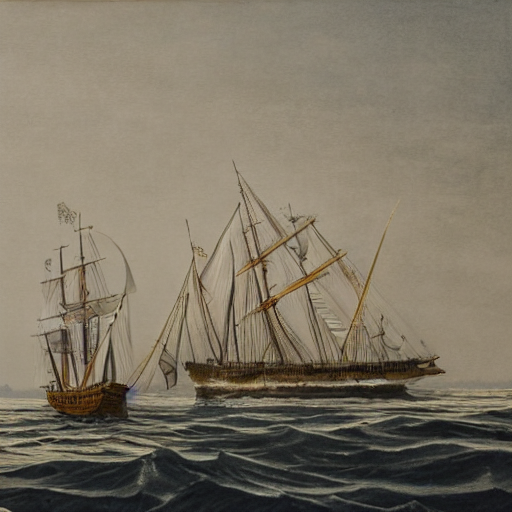

In [18]:
generator = torch.Generator(device=device).manual_seed(SEED)
imagen_despues = pipe(
    PROMPT,
    generator=generator,
    num_inference_steps=NUM_STEPS,
    guidance_scale=GUIDANCE,
).images[0]

imagen_despues.save("imagenes/despues_sailing_ship.png")
imagen_despues

  0%|          | 0/50 [00:00<?, ?it/s]

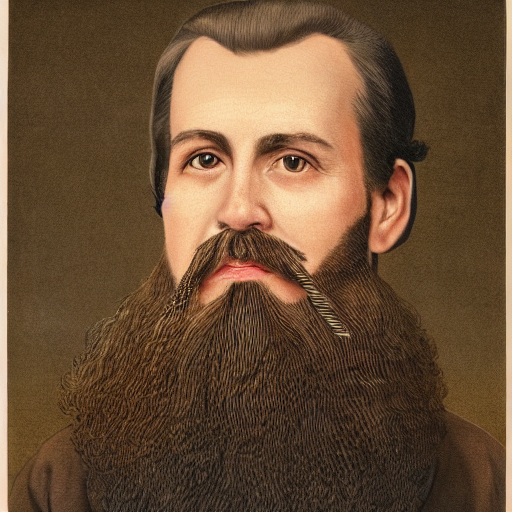

In [19]:
# Prompt de control. Si tambien cambia de tecnica, la LoRA ha aprendido una estetica
# generalizable; si solo cambiase el barco, habria memorizado contenido concreto.
generator = torch.Generator(device=device).manual_seed(SEED)
imagen_despues_control = pipe(
    PROMPT_CONTROL,
    generator=generator,
    num_inference_steps=NUM_STEPS,
    guidance_scale=GUIDANCE,
).images[0]

imagen_despues_control.save("imagenes/despues_portrait.png")
imagen_despues_control

### Barrido de intensidad del adaptador

`adapter_weights` multiplica la contribución de la LoRA en inferencia, sin alterar los pesos
guardados. A escala 0 debe recuperarse la imagen del modelo base, lo que confirma que los pesos
originales permanecen intactos y que el adaptador se suma correctamente.

El barrido se extiende más allá de 1 deliberadamente: permite comprobar si la dirección aprendida
es correcta y hasta dónde puede llevarse sin degradar la imagen.

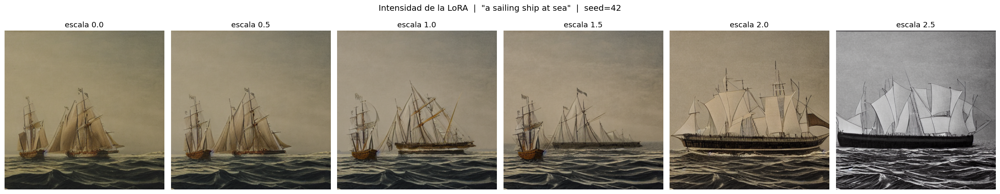

In [20]:
escalas = [0.0, 0.5, 1.0, 1.5, 2.0, 2.5]

fig, axes = plt.subplots(1, len(escalas), figsize=(22, 4.5))
for ax, escala in zip(axes, escalas):
    pipe.set_adapters([adapter_name], adapter_weights=[escala])
    gen = torch.Generator(device=device).manual_seed(SEED)
    img = pipe(PROMPT, generator=gen, num_inference_steps=NUM_STEPS, guidance_scale=GUIDANCE).images[0]
    ax.imshow(img); ax.set_title(f"escala {escala}"); ax.axis("off")

fig.suptitle(f'Intensidad de la LoRA  |  "{PROMPT}"  |  seed={SEED}', fontsize=13)
plt.tight_layout()
plt.savefig("imagenes/barrido_escala.png", dpi=110, bbox_inches="tight")
plt.show()

### Comparativa final

Figura entregable: para cada prompt, el modelo base, la LoRA a escala nominal y la LoRA a escala 2,5.

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

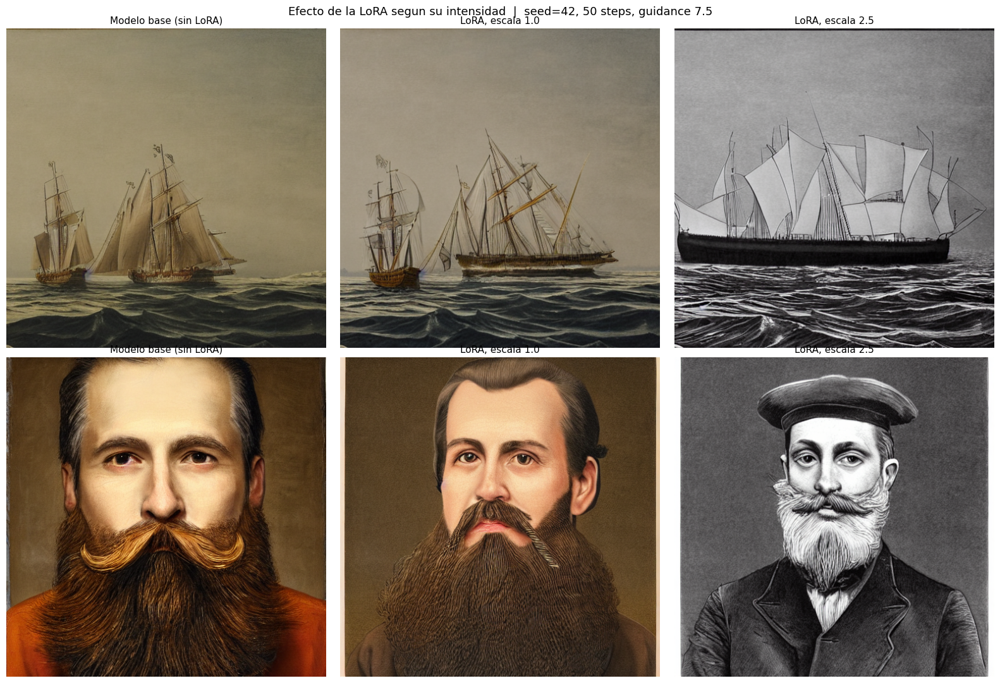

In [21]:
finales = {}
pipe.set_adapters([adapter_name], adapter_weights=[2.5])
for nombre, prompt in [("barco", PROMPT), ("retrato", PROMPT_CONTROL)]:
    gen = torch.Generator(device=device).manual_seed(SEED)
    finales[nombre] = pipe(prompt, generator=gen,
                           num_inference_steps=NUM_STEPS, guidance_scale=GUIDANCE).images[0]

finales["barco"].save("imagenes/despues_sailing_ship_x2.5.png")
finales["retrato"].save("imagenes/despues_portrait_x2.5.png")

fig, axes = plt.subplots(2, 3, figsize=(16, 11))
filas = [
    (PROMPT, imagen_antes, imagen_despues, finales["barco"]),
    (PROMPT_CONTROL, imagen_antes_control, imagen_despues_control, finales["retrato"]),
]
titulos = ["Modelo base (sin LoRA)", "LoRA, escala 1.0", "LoRA, escala 2.5"]
for fila, (prompt, *imgs) in zip(axes, filas):
    for ax, img, t in zip(fila, imgs, titulos):
        ax.imshow(img); ax.set_title(t, fontsize=11); ax.axis("off")

fig.suptitle(f'Efecto de la LoRA segun su intensidad  |  seed={SEED}, {NUM_STEPS} steps, guidance {GUIDANCE}',
             fontsize=13)
plt.tight_layout()
plt.savefig("imagenes/comparativa_final.png", dpi=120, bbox_inches="tight")
plt.show()

pipe.set_adapters([adapter_name], adapter_weights=[1.0])

### Lectura de los resultados

**El adaptador ha aprendido estilo, no contenido.** El prompt de control, un retrato sin ninguna
relación con el contenido del dataset, también cambia de técnica: el rostro deja de ser
fotorrealista y la barba pasa a construirse por trazos en lugar de por textura continua. Si la
LoRA hubiera memorizado el contenido de las ilustraciones, el retrato habría permanecido inalterado.

**La dirección aprendida es correcta, pero el factor de escala nominal la aplica de forma tímida.**
A escala 1,0 la composición gana definición lineal (jarcias dibujadas trazo a trazo, contornos más
duros) mientras conserva la paleta del modelo base. La estética de grabado emerge por completo
a partir de 2,0, y a 2,5 el resultado es blanco y negro con el oleaje resuelto íntegramente mediante
rayado, sin degradación ni artefactos.

Esto se explica por el factor de escala de la LoRA, `alpha / r`, que con `alpha = r = 8` vale 1,0.
Un entrenamiento con `lora_alpha = 32` habría producido a escala 1,0 un resultado equivalente al que
aquí se obtiene a 2,5. Son dos vías hacia el mismo punto, con la diferencia de que la intensidad en
inferencia es gratuita y reversible: esa graduación es precisamente la ventaja de los adaptadores
frente a un finetuning completo, donde lo entrenado es lo único disponible.

# 7. Subida a Hugging Face

Se publica el adaptador, que son unos pocos MB, acompañado de su model card. El token de escritura
se lee del panel de secretos de Colab bajo el nombre `HF_TOKEN`.

In [ ]:
from huggingface_hub import login, whoami, HfApi
from google.colab import userdata

login(token=userdata.get("HF_TOKEN"))

usuario = whoami()["name"]
repo_id = f"{usuario}/{REPO_NOMBRE}"
print("Repo destino:", repo_id)

In [ ]:
model_card = f"""---
license: creativeml-openrail-m
base_model: {pretrained_model_name}
tags:
  - stable-diffusion
  - lora
  - text-to-image
  - diffusers
datasets:
  - {dataset_name}
---

# LoRA: ilustraciones de libros antiguos sobre Stable Diffusion v1-4

Adaptador LoRA entrenado sobre `{pretrained_model_name}` con el dataset
[`{dataset_name}`](https://huggingface.co/datasets/{dataset_name}), compuesto por ilustraciones
grabadas de libros publicados entre 1800 y 1900.

## Configuracion de entrenamiento

| Parametro | Valor |
|---|---|
| Rango (r) | {lora_rank} |
| Alpha | {lora_alpha} |
| Modulos | to_q, to_k, to_v, to_out.0 |
| Muestras | {len(dataset)} |
| Epocas | {num_epochs} |
| Batch size | {batch_size} |
| Learning rate | {learning_rate} |
| Resolucion | {resolution}x{resolution} |
| Precision | fp32 |

Las muestras se filtraron por caption en ingles de al menos {MIN_CARACTERES} caracteres, usando las
columnas `{COL_IMAGEN}` e `{COL_TEXTO}`. Las imagenes se redimensionaron por el lado corto y se
recortaron al centro para preservar la relacion de aspecto original.

## Uso

```python
from diffusers import StableDiffusionPipeline
import torch

pipe = StableDiffusionPipeline.from_pretrained("{pretrained_model_name}", torch_dtype=torch.float16).to("cuda")
pipe.load_lora_weights("{repo_id}")

image = pipe("a sailing ship at sea", num_inference_steps=50, guidance_scale=7.5).images[0]
```

## Intensidad del adaptador

Con el factor de escala nominal (`alpha / r` = 1.0) el adaptador produce un cambio de estilo visible
pero parcial: la composicion gana definicion lineal mientras conserva la paleta del modelo base. La
estetica de grabado del dataset emerge por completo escalando el adaptador por encima de 1, sin
degradacion de la imagen:

```python
pipe.set_adapters(["{adapter_name}"], adapter_weights=[2.5])
```

Un entrenamiento equivalente con `lora_alpha=32` habria producido este comportamiento a escala 1.0.
"""

with open(os.path.join(OUTPUT_DIR, "README.md"), "w") as f:
    f.write(model_card)

print(model_card[:600], "...")

In [ ]:
api = HfApi()
api.create_repo(repo_id=repo_id, repo_type="model", exist_ok=True)
api.upload_folder(
    folder_path=OUTPUT_DIR,
    repo_id=repo_id,
    repo_type="model",
    commit_message="LoRA finetuneada con oldbookillustrations",
)

url = f"https://huggingface.co/{repo_id}"
print("Subido a:", url)

# Entregable: fichero .txt con el enlace al repositorio
with open("huggingface_link.txt", "w") as f:
    f.write(url + "\n")

# 8. Recarga del modelo desde Hugging Face

Última comprobación: cargar el modelo base limpio, descargar el adaptador publicado desde el
repositorio y generar con él. Verifica que lo subido funciona para cualquier usuario.

In [ ]:
repo_id = "adrianoropezal/sd-v1-4-oldbook-illustrations-lora"

torch.cuda.empty_cache()

pipe_hub = StableDiffusionPipeline.from_pretrained(
    pretrained_model_name,
    safety_checker=None,
    requires_safety_checker=False,
).to(device)

# Descarga el adaptador desde el repositorio (unos pocos MB) y lo monta sobre el modelo base
pipe_hub.load_lora_weights(repo_id)

generator = torch.Generator(device=device).manual_seed(SEED)
imagen_hub = pipe_hub(
    PROMPT,
    generator=generator,
    num_inference_steps=NUM_STEPS,
    guidance_scale=GUIDANCE,
    cross_attention_kwargs={"scale": 2.5},
).images[0]

imagen_hub.save("imagenes/desde_hub_sailing_ship.png")
imagen_hub

# 9. Conclusiones

**Sobre la eficiencia de LoRA.** Se han entrenado 1.594.368 parámetros de los 861.115.332 que tiene
la UNet, un 0,19%, y el artefacto resultante pesa unos pocos MB frente a los ~3,4 GB del modelo
completo. Ese adaptador basta para desplazar el comportamiento del modelo hacia un estilo gráfico
que antes no producía ante prompts neutros.

**Sobre la evaluación.** La loss media por época se movió entre 0,1433 y 0,1580 sin tendencia
apreciable, pese a que el modelo sí estaba aprendiendo. En difusión, el muestreo aleatorio de
timesteps domina la señal de la loss y la hace inútil como criterio de parada. La evaluación tuvo
que ser visual.

**Sobre estilo frente a contenido.** El uso de un segundo prompt sin relación con el dataset resultó
decisivo para distinguir ambos casos. Al cambiar también de técnica, quedó descartado que el
adaptador hubiera memorizado el contenido de las ilustraciones.

**Sobre el factor de escala.** El resultado inicial parecía insuficiente, pero el barrido de
intensidad demostró que la dirección aprendida era correcta y solo faltaba amplitud. Graduar el
adaptador en inferencia resolvió el problema sin reentrenar, algo imposible en un finetuning
completo. `alpha` y `adapter_weights` actúan sobre el mismo factor de escala, uno en entrenamiento
y otro en inferencia.

**Posibles mejoras.** Entrenar con `lora_alpha = 32` para que el comportamiento deseado se obtenga
a escala nominal; ampliar el número de muestras más allá del 20%; y traducir las captions en francés
y alemán en lugar de descartarlas, lo que recuperaría cerca de un 19% del dataset.

---

### Entregables

1. Este notebook.
2. `huggingface_link.txt` con el enlace al repositorio del modelo.
3. `imagenes/antes_sailing_ship.png` y `imagenes/despues_sailing_ship_x2.5.png`, junto con
   `imagenes/comparativa_final.png` y `imagenes/barrido_escala.png`.